# clock/04.4 — OOD generalization of the completion signal

Load the attention heads selected by a completion-mask run trained on the **Python**
condition-check dataset, compute a **per-head mean** intervention signal (§6.1 of `04.3_eval`),
then check whether the same signal transfers off-the-shelf to:

1. **In-distribution sanity** — python `build_example` (should look the same as `04.3`).
2. **Same shape, new language** — cpp `build_example` (new `lang="cpp"` support in `condition_data.py` + `multiline_prompts.py`).
3. **Hardcoded C++ prompts** — small, hand-written C++ programs, more freeform than `build_example`'s `check_conditions` shape.

The mask is **NOT retrained** on any of these — that's the whole point. This is an off-the-shelf
generalization test: does the intervention direction learned on python condition-check still
push a dest toward the flipped verdict when the dest is C++, or a different shape entirely?

Follows the `04.3_eval` conventions:
- augmentation `code = code.replace("\n", "    \n") + "    "`
- `PIVOT_POS = -2` (the `"    \n"` pivot)
- readout at position `-1` (never at the patched `-2`)


In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, random, logging

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,2,6")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append("../..")


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.utils import logging_utils

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")


2026-07-05 11:20:28 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-05 11:20:28 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-05 11:20:28 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-05 11:20:28 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-05 11:20:28 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-05 11:20:28 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-05 11:20:40 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-05 11:20:40 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-05 11:20:40 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load the trained completion mask (Python-only) + selected heads

In [246]:
# ── loaders for completion-mask results (scripts/clock/train_completion_mask.py) ──
from src.goals.oid_gaze import cache_root
from src.goals.head_loc_attn import HeadMask

COMPLETION_VERSION = "conditions"
# swap to "completion_mask_gaze" if you want the gaze-obj variant instead
MASK_KIND = "completion_mask"
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, COMPLETION_VERSION), MASK_KIND)


def list_completion_masks():
    if not os.path.isdir(COMPLETION_MASK_ROOT):
        return []
    items = [
        (t, os.path.join(COMPLETION_MASK_ROOT, t),
         os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
        for t in os.listdir(COMPLETION_MASK_ROOT)
        if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))
    ]
    return sorted(items, key=lambda x: x[2], reverse=True)


def load_completion_mask(tag=None):
    items = list_completion_masks()
    assert items, f"no {MASK_KIND} results under {COMPLETION_MASK_ROOT}"
    if tag is None:
        d = items[0][1]
    else:
        matches = [it for it in items if tag in it[0]]
        assert matches, f"no run under {COMPLETION_MASK_ROOT} contains tag {tag!r}"
        d = matches[0][1]
    ck = torch.load(os.path.join(d, "mask.pt"), map_location="cpu", weights_only=False)
    ck["dir"] = d
    return ck


def completion_mask_to_headmask(ck):
    layers = [int(x) for x in ck["layers"]]
    nH = ck["mask_values"].shape[1]
    hm = HeadMask(len(layers), nH)
    with torch.no_grad():
        hm.values.copy_(ck["mask_values"])
    return hm


In [247]:
# ── pick a mask and inspect it ──
# COMPLETION_MASK_TAG = None    # newest by mtime
COMPLETION_MASK_TAG = "lam10.0"   # completion_mask
# COMPLETION_MASK_TAG = "lam100.0"   # completion_mask_gaze

CK     = load_completion_mask(COMPLETION_MASK_TAG)
layers = [int(x) for x in CK["layers"]]
mv     = CK["mask_values"].numpy()
hist   = CK["history"]
meta   = CK["meta"]
sel_heads    = [tuple(int(z) for z in lh) for lh in CK["decision_heads"]]
thr    = float(meta.get("sel_threshold", 0.9))

print(f"[{os.path.basename(CK['dir'])}]")
print(f"  layers {layers[0]}-{layers[-1]} ({len(layers)} masked) · patch_tokens={CK['patch_tokens']} · "
      f"direction={meta['direction']} · same={meta['same']} · N={meta['n_pairs']}")
print(f"  {len(sel_heads)} decision heads (mask>{thr}) · "
      f"final train score={hist['train_score'][-1]:+.4f} · val score={hist['val_score'][-1]:+.4f}")
ranked = sorted(sel_heads, key=lambda lh: mv[layers.index(lh[0]), lh[1]], reverse=True)
print("  top decision heads:", [f"L{l}H{h}" for (l, h) in ranked[:15]])


[diff_pt-2_both_L0-64_lam10.0_n600]
  layers 0-63 (64 masked) · patch_tokens=[-2] · direction=both · same=False · N=600
  251 decision heads (mask>0.5) · final train score=+7.7008 · val score=+7.2003
  top decision heads: ['L13H22', 'L14H25', 'L15H23', 'L20H28', 'L21H0', 'L22H17', 'L22H19', 'L22H29', 'L23H14', 'L25H19', 'L27H16', 'L28H13', 'L28H27', 'L28H29', 'L30H3']


In [248]:
# ── selected heads (mask > thr) as a set + a binary HeadMask for patching ──
SEL_THRESHOLD = 0.5
n_layer_total = mt.model.config.num_hidden_layers
n_heads_total = mv.shape[1]

full_mask = np.full((n_layer_total, n_heads_total), np.nan, dtype=float)
for li, L in enumerate(layers):
    full_mask[L] = mv[li]

sel_set   = {(int(l), int(h)) for l, h in np.argwhere(full_mask > SEL_THRESHOLD)}
sel_heads = sorted(sel_set)

# Default set used for interventions in §3–§5. The separator-analysis cells below overwrite
# this with filtered_sel_heads; seeding it here keeps §3–§5 runnable even if that step is skipped.
DECISION_HEADS = sel_heads

mask_bin = HeadMask(len(layers), n_heads_total)
with torch.no_grad():
    mask_bin.values.zero_()
    for (l, h) in sel_set:
        mask_bin.values[layers.index(l), h] = 1.0
print(f"mask_bin: {int(mask_bin.values.sum().item())} heads = 1.0  (binary @ thr {SEL_THRESHOLD})")
print(f"DECISION_HEADS: {len(DECISION_HEADS)} heads (default = sel_heads; override via the filter cell)")


def get_mask_bin(heads):
    """HeadMask (on CPU) with 1.0 for `heads`, 0.0 elsewhere. Layer index space is `layers`."""
    hm = HeadMask(len(layers), n_heads_total)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[layers.index(l), h] = 1.0
    return hm


mask_bin: 251 heads = 1.0  (binary @ thr 0.5)
DECISION_HEADS: 251 heads (default = sel_heads; override via the filter cell)


In [249]:
# -- selected heads: does OV write at the pivot separate stay (ml) vs move-on (sl)? --
from torch.nn.functional import cosine_similarity as _cos
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

N_DECISION = 100
PIVOT_POS = -2

# minimal pairs: source IS dest (same spec, ml vs sl differ only at the target line)
dec_pairs = build_completion_pairs(
    mt, n_pairs=N_DECISION, direction="both", same=True,
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]), seed=2024,
)
stay_prompts = [p.source.ml_prompt for p in dec_pairs]    # incomplete target  -> stay/continue
move_prompts = [p.source.sl_prompt for p in dec_pairs]    # complete target    -> moved_on
print(f"{len(dec_pairs)} minimal pairs; reading {len(sel_heads)} selected heads at pos {PIVOT_POS}")

# per-head OV write at the pivot for both situations (left-pad => -2 aligns across lengths)
stay_tok = prepare_input(stay_prompts, tokenizer=mt, padding_side="left")
move_tok = prepare_input(move_prompts, tokenizer=mt, padding_side="left")
_, stay_h = collect_head_steering_vecs(mt, stay_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)
_, move_h = collect_head_steering_vecs(mt, move_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)


rows = []
for (l, h) in sorted(sel_heads):
    stay = stay_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    move = move_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    per_pair = _cos(stay, move, dim=1)                       # (N,)  cos within each spec
    mean_vs_mean = _cos(stay.mean(0), move.mean(0), dim=0).item()
    rows.append((l, h, per_pair.mean().item(), per_pair.std().item(), mean_vs_mean))

rows.sort(key=lambda r: r[2])   # most-separating (lowest cosine) first
print(f"\n{'layer':>5} {'head':>5} {'per-pair cos (mean+/-std)':>26} {'mean-vs-mean cos':>18}")
for l, h, m, s, mm in rows:
    print(f"{l:5d} {h:5d} {m:>14.3f} +/-{s:<7.3f} {mm:>18.3f}")

  built 25/100 pairs (27 attempts)
  built 50/100 pairs (54 attempts)
  built 75/100 pairs (79 attempts)
  built 100/100 pairs (104 attempts)
built 100 pairs from 104 attempts
100 minimal pairs; reading 251 selected heads at pos -2

layer  head  per-pair cos (mean+/-std)   mean-vs-mean cos
   51     4          0.006 +/-0.340               -0.070
   49    10          0.027 +/-0.239                0.051
   44    28          0.120 +/-0.193                0.101
   31    10          0.129 +/-0.205                0.010
   47    31          0.155 +/-0.233                0.595
   13    22          0.174 +/-0.214                0.221
   40    32          0.177 +/-0.222                0.084
   48    26          0.178 +/-0.197                0.266
   14    25          0.179 +/-0.204                0.327
   48    28          0.181 +/-0.210                0.210
   51     2          0.207 +/-0.299                0.307
   28    13          0.228 +/-0.221                0.223
   43    16          0.24

In [262]:
filtered_sel_heads = [
    (l, h)
    for (l, h), m, s, mm in zip(
        sel_heads, [r[2] for r in rows], [r[3] for r in rows], [r[4] for r in rows]
    )
    if m < 0.6
]
print(len(filtered_sel_heads), len(sel_heads))


#######################################################################
DECISION_HEADS = filtered_sel_heads
# DECISION_HEADS = sel_heads
#######################################################################
len(DECISION_HEADS)

137 251


137

In [269]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores


# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 150
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
# flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
LO_LAYER = 0
head_idx_to_gaze_scores = []
for layer_idx in range(LO_LAYER, gaze_scores.shape[0]):
    for head_idx in range(gaze_scores.shape[1]):
        head_idx_to_gaze_scores.append(((layer_idx, head_idx), gaze_scores[layer_idx, head_idx]))
head_idx_to_gaze_scores = sorted(head_idx_to_gaze_scores, key=lambda x: x[1], reverse=True)[:TOP_K]

gaze_heads = [(l, h) for (l, h), _ in head_idx_to_gaze_scores]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-150 gaze heads  (compare_with='mean', q_span=15)  score range [2.579, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 135 more)


decision heads: 137  ·  gaze top-150: 150 in masked band
overlap (both): 9  ·  Jaccard within band = 0.032
  overlap heads: ['L25H18', 'L25H19', 'L40H0', 'L41H17', 'L42H22', 'L42H31', 'L43H29', 'L43H5', 'L8H3']


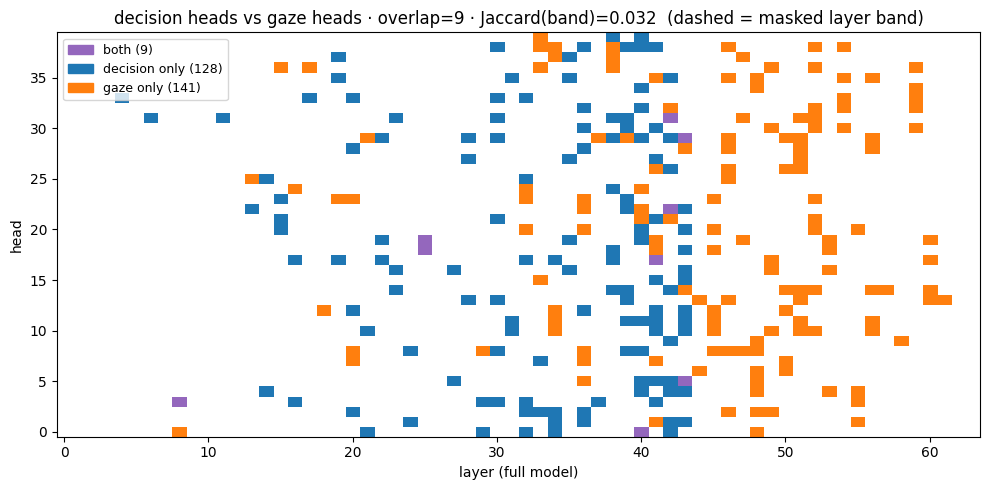

In [270]:
# Plot the gaze heads with DECISION_HEADS overlaid
# needs `gaze_heads` (gaze-score cell) and `DECISION_HEADS` (§1 selection / filter cell).
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

gaze_set  = {(int(l), int(h)) for (l, h) in gaze_heads}
PATCH_SET = set(DECISION_HEADS)
both      = PATCH_SET & gaze_set
mask_only = PATCH_SET - gaze_set
gaze_only = gaze_set - PATCH_SET

# the mask can only select WITHIN its masked layer band — restrict gaze there for a fair
# Jaccard, but plot the full picture.
band = set(layers)
gaze_in_band = {(l, h) for (l, h) in gaze_set if l in band}
jac = len(both) / max(len(PATCH_SET | gaze_in_band), 1)
print(f"decision heads: {len(PATCH_SET)}  ·  gaze top-{len(gaze_set)}: "
      f"{len(gaze_in_band)} in masked band")
print(f"overlap (both): {len(both)}  ·  Jaccard within band = {jac:.3f}")
print("  overlap heads:", sorted(f"L{l}H{h}" for (l, h) in both))

# categorical grid: 0 none · 1 gaze-only · 2 decision-only · 3 both
cat = np.zeros((n_layer_total, n_heads_total))
for (l, h) in gaze_only: cat[l, h] = 1
for (l, h) in mask_only: cat[l, h] = 2
for (l, h) in both:      cat[l, h] = 3
cats_cmap = ListedColormap(["#ffffff", "#ff7f0e", "#1f77b4", "#9467bd"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(cat.T, aspect="auto", cmap=cats_cmap, vmin=0, vmax=3,
          origin="lower", interpolation="nearest")
ax.axvline(layers[0] - 0.5, color="k", ls="--", lw=0.7)
ax.axvline(layers[-1] + 0.5, color="k", ls="--", lw=0.7)
ax.set_xlabel("layer (full model)"); ax.set_ylabel("head")
ax.set_title(f"decision heads vs gaze heads · overlap={len(both)} · "
             f"Jaccard(band)={jac:.3f}  (dashed = masked layer band)")
handles = [mpatches.Patch(color=c, label=lab) for c, lab in [
    ("#9467bd", f"both ({len(both)})"),
    ("#1f77b4", f"decision only ({len(mask_only)})"),
    ("#ff7f0e", f"gaze only ({len(gaze_only)})"),
]]
ax.legend(handles=handles, loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()


## 2. Per-head **mean** intervention signal — computed on Python condition-check

Same recipe as `04.3_eval` §6.1: pull the source o_proj-input at the pivot for `N_MEAN_SRC`
sources drawn from `build_completion_pairs`, average over sources → one `(n_layers, n_embd)` tensor
that acts as the "general" source signal.  Two choices:

- `HP_DIRECTION = "sl->ml"`  → source style = `sl` (moved_on)  → mean = **move-on** signal → pushes a dest to move on
- `HP_DIRECTION = "ml->sl"`  → source style = `ml` (multiline/stay) → mean = **stay** signal → pushes a dest to stay

Then in §3–§5 we patch selected heads' OV at the pivot with this mean signal on OOD dests.

In [193]:
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import get_o_proj_inputs_batch
from src.tokens import prepare_input

# ── config for the mean signal ──
HP_DIRECTION   = "sl->ml"          # "sl->ml" = MOVE-ON mean (push a stay dest to move on)
                                   # "ml->sl" = STAY    mean (push a move-on dest to stay)
PATCH_POS      = int(CK["patch_tokens"][0]) if len(CK["patch_tokens"]) == 1 else -2
N_MEAN_SRC     = 200
MEAN_SRC_BATCH = 16
MEAN_SEED      = 1234

src_style = "sl" if HP_DIRECTION == "sl->ml" else "ml"
sig_name  = "move-on" if src_style == "sl" else "stay"
print(f"target: mean '{sig_name}' signal ({HP_DIRECTION}) at POS={PATCH_POS} over N={N_MEAN_SRC}")

target: mean 'move-on' signal (sl->ml) at POS=-2 over N=200


In [194]:
# ── compute the mean signal, or load from local disk cache if we already did ──
import json, hashlib
from src.utils import env_utils

OVERWRITE_MEAN = False   # set True to force recompute

NB_CACHE_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_cache")
os.makedirs(NB_CACHE_DIR, exist_ok=True)

_mean_cfg = dict(
    model=MODEL_NAME, kind="mean_signal", direction=HP_DIRECTION, n_src=N_MEAN_SRC,
    same=bool(meta.get("same", False)),
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]),
    patch_pos=int(PATCH_POS), layers=list(int(l) for l in layers), seed=MEAN_SEED,
)
_key = hashlib.md5(json.dumps(_mean_cfg, sort_keys=True, default=str).encode()).hexdigest()[:10]
_mean_path = os.path.join(
    NB_CACHE_DIR,
    f"mean_signal_{HP_DIRECTION.replace('->', '_')}_N{N_MEAN_SRC}_{_key}.pt",
)

if not OVERWRITE_MEAN and os.path.exists(_mean_path):
    mean_signal = torch.load(_mean_path, map_location="cpu")
    print(f"loaded mean_signal from cache: {_mean_path}")
    print("mean_signal:", tuple(mean_signal.shape))
else:
    mean_pairs = build_completion_pairs(
        mt, n_pairs=N_MEAN_SRC, direction=HP_DIRECTION,
        same=bool(meta.get("same", False)),
        patch_tokens=tuple(int(t) for t in CK["patch_tokens"]),
        seed=MEAN_SEED,
    )
    mean_src_prompts = [p.source.prompt(src_style) for p in mean_pairs]
    print(f"sampled {len(mean_src_prompts)} sources (style={src_style}) for the mean '{sig_name}' signal")

    # batched o_proj cache at PATCH_POS across all masked layers -> mean over sources
    # get_o_proj_inputs_batch(..., token_positions=[POS]) returns {layer: (b, 1, n_embd)};
    # stack over layers and index the singleton position dim -> (b, n_layers, n_embd).
    _acc, n_seen = None, 0
    for i in range(0, len(mean_src_prompts), MEAN_SRC_BATCH):
        chunk = mean_src_prompts[i : i + MEAN_SRC_BATCH]
        c = get_o_proj_inputs_batch(mt, chunk, layers, token_positions=[PATCH_POS])
        stk = torch.stack([c[l][:, 0] for l in layers], dim=1)  # (b, n_layers, n_embd)
        _acc = stk.sum(0) if _acc is None else _acc + stk.sum(0)
        n_seen += stk.shape[0]
    mean_signal = (_acc / n_seen).float()  # (n_layers, n_embd)
    torch.save(mean_signal, _mean_path)
    print("mean_signal shape:", tuple(mean_signal.shape), "from", n_seen, "sources")
    print(f"saved mean_signal to cache: {_mean_path}")

loaded mean_signal from cache: /disk/u/arnab/Codes/Projects/goals/results/notebook_cache/mean_signal_sl_ml_N200_bb320d66a8.pt
mean_signal: (64, 5120)


## 3. In-distribution sanity — python `build_example`

If everything is wired up correctly, this should look the same as `04.3_eval` §6.1 (mean-replace):
patching the selected heads' OV with the move-on mean at the pivot should visibly redirect the
dest away from the "stay/continue" continuation.

In [231]:
def test_aug(prompt: str) -> str:
    """Turn each `\\n` inside the final <code> block into `    \\n` so trailing-whitespace
    tokenization is stable (used before tokenizing for latent extraction / patching)."""
    code_split = prompt.split("<code>")
    code_segment = code_split[-1]
    prefix = "<code>".join(code_split[:-1])
    code_segment = code_segment.replace("\n", "    \n")
    return prefix + "<code>" + code_segment

In [241]:
from src.functional import generate_with_patch
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.goals.goalscope import headpatched_generate

def render_prompt(example):
    """apply the augmentation + trailing `    ` so PIVOT=-2 lands on `    \n` at the pivot."""
    return replace_in_code_newline_with_tabnewline(example["full_prompt"]) + "   "


def run_intervention(tok, decision_heads, n_gen=32, patch_pos=[PATCH_POS], alpha=1.0):
    """Clean vs mean-replace generation for a single prompt."""
    clean = generate_with_patch(
        mt, inputs=tok, n_gen_per_prompt=1, max_new_tokens=n_gen,
        do_sample=False, remove_prefix=True,
    )[0]
    patched = headpatched_generate(
        mt, dest_inputs=tok, src_o_proj_inps=mean_signal,
        mask=get_mask_bin(decision_heads),
        layers=layers, max_new_tokens=n_gen,
        n_steer_tokens=1, patch_input_positions=patch_pos,
        alpha=alpha
    )
    return clean, patched


NAMING = "letters"
N_GEN  = 32

# dest style is the OPPOSITE of source (we're pushing dest to flip)
dst_style_full = "singleline" if src_style == "ml" else "multiline"

example_py = build_example(
    mt=mt, rng=random.Random(112358),
    target_slot=1, n_conditions=4,
    mode="chat", style=dst_style_full, naming=NAMING, lang="python",
)
# prompt_py = render_prompt(example_py)
prompt_py = test_aug(example_py["full_prompt"]) + "   " 
tok_py = prepare_input(prompt_py, tokenizer=mt, padding_side="left")

clean_py, patched_py = run_intervention(tok_py, DECISION_HEADS, n_gen=N_GEN, alpha=1.0)
rich_print(f"[bold]python | clean          [/bold] [white]{escape(prompt_py)}[/white][sea_green3]{escape(clean_py)}[/sea_green3]")
rich_print(f"[bold]python | mean-replace ({len(DECISION_HEADS)})[/bold] [white]{escape(prompt_py)}[/white][salmon1]{escape(patched_py)}[/salmon1]")


python | clean           <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's proper divisors is greater than n
2. n is divisible by 16
3. n is a perfect cube
4. the product of n's digits is greater than 0

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = sum(d for d in range(1, abs(n)) if n % d == 0)    
    a = n > 0 and a > n    
    b = n % 16    
    b = b == 0    
    c = round(n ** (1/3)) ** 3    
    c = c == n    
    d =

python | mean-replace (141) <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's proper divisors is greater than n
2. n is divisible by 16
3. n is a perfect cube
4. the product of n's digits is greater than 0

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = sum(d for d in range(1, abs(n)) if n % d == 0)    
    a = n > 0 and a > n    
    b = n % 16    
    c = round(n ** (1/3)) ** 3 == n    
    d = n != 0 and all(int(digit) > 0

In [242]:
# # ── §3 attention: clean vs mean-replace on the python dest ────────────────────
# from src.attention import get_attention_matrices, show_interactive_attention
# from src.goals.head_loc_attn import make_head_replacement_patch_interface

# P_py = len(tok_py.input_ids[0])  # dest-prompt length
# pivot_abs_py = P_py + PATCH_POS  # absolute index of the patched pivot

# # guard: prompt must tokenize identically as a prefix of prompt+gen so pivot_abs is correct
# _clean_ids = prepare_input(prompt_py + clean_py, tokenizer=mt).input_ids[0]
# assert _clean_ids[:P_py].tolist() == tok_py.input_ids[0].tolist(), (
#     "retokenization drift: prompt_py is not a clean prefix of prompt_py + clean_py"
# )

# clean_attn_py = get_attention_matrices(
#     input=prompt_py + clean_py,
#     mt=mt,
#     value_weighted=True,
# )
# show_interactive_attention(
#     attn_info=clean_attn_py,
#     selected_heads=sorted(DECISION_HEADS),
#     start_from=0,
#     agg="mean",
#     normalize="row_max",
#     cmap="Greens",
#     title=f"python | clean attention — {len(DECISION_HEADS)} decision heads",
#     track_conditions=example_py["spec"],
#     intervened_positions=[pivot_abs_py],
#     height=None,
# )

# # head-patched attention via the SAME head-replacement transplant used for steering
# _patched_ids = prepare_input(prompt_py + patched_py, tokenizer=mt).input_ids[0]
# assert _patched_ids[:P_py].tolist() == tok_py.input_ids[0].tolist(), (
#     "retokenization drift: prompt_py is not a clean prefix of prompt_py + patched_py"
# )

# patch_iface_py = make_head_replacement_patch_interface(
#     src_head_inps=mean_signal,
#     mask=get_mask_bin(DECISION_HEADS),
#     layers=layers,
#     patch_positions=[pivot_abs_py],
# )
# patched_attn_py = get_attention_matrices(
#     input=prompt_py + patched_py,
#     mt=mt,
#     value_weighted=True,
#     patch_interface=patch_iface_py,
# )
# show_interactive_attention(
#     attn_info=patched_attn_py,
#     selected_heads=sorted(DECISION_HEADS),
#     start_from=0,
#     agg="mean",
#     normalize="row_max",
#     cmap="Reds",
#     title=f"python | mean-replace attention — {len(DECISION_HEADS)} decision heads",
#     track_conditions=example_py["spec"],
#     intervened_positions=[pivot_abs_py],
#     height=None,
# )


## 3.1 In-distribution, harder — hardcoded **Python** programs (multi-line conditions)

Same `check_conditions(n)` shape as `build_example`, but each condition is a genuine multi-line
algorithm — loops, predicates, guards / error-checking — instead of a one-liner. The prefixes are
**hand-written** (not sampled by `build_example`), so this is a mild OOD test: does the same
`mean_signal` (learned on the simple python condition-check) still flip *stay → move-on* when the
surrounding code is more complex?

Each program:
- lists 4 conditions and implements **condition 1 fully** (multi-line, with a loop + a guard),
- **starts condition 2** with a single intermediate statement at 4-space indent — the pivot,
- leaves conditions 3–4 unwritten.

At the pivot the natural continuation is *stay* (finish condition 2's loop); the move-on signal
should push the dest to abandon condition 2 and jump to condition 3. Prompt construction mirrors
§3 exactly: `apply_chat_template(...)` → `test_aug(...) + "   "`, pivot at `PATCH_POS`.


In [264]:
from src.goals.functional import apply_chat_template

def make_py_instruction(conditions):
    """Reproduce ConditionSpec.render_instruction(name_rule="natural") for hand-written conditions."""
    body = "\n".join(f"{i + 1}. {t}" for i, t in enumerate(conditions))
    return "\n".join([
        "Write a Python program that implements a function `check_conditions` which, "
        "given an integer n, checks the following conditions:",
        "",
        body,
        "",
        "For each condition, in the order listed, assign the boolean result of the check to "
        "its own local variable. After all conditions have been checked, use a SINGLE print "
        "statement that, using those variables, reports whether each condition passed "
        "individually and whether all of them passed collectively.",
        "Compute each condition's boolean result inside `check_conditions` (one local variable "
        "per condition); do not define any helper functions.",
        "Do not include any comments in your code.",
    ])

STUB = "def check_conditions(n: int):\n"

def make_py_prompt(conditions, body):
    """Chat-format the instruction + (stub + body) prefix, then apply the §3 pivot augmentation."""
    full = apply_chat_template(mt=mt, user_query=make_py_instruction(conditions),
                               incomplete_code=STUB + body)
    return test_aug(full) + "   "

# Each program: 4 conditions, condition 1 fully implemented (loop + guard), condition 2 started
# with one 4-space statement (the pivot), conditions 3-4 left for the model.
PY_PROGRAMS = [
    {   # A — prime / digit-sum / repeated-digits / magnitude
        "conditions": [
            "n is a prime number",
            "the sum of n's digits is divisible by 3",
            "n has no repeated digits",
            "n is greater than 100",
        ],
        "id_substrs": [["prime"], ["divisible by 3"], ["repeated"], ["greater than 100"]],
        "body": (
            "    is_prime = n > 1\n"
            "    for i in range(2, int(n ** 0.5) + 1):\n"
            "        if n % i == 0:\n"
            # "            is_prime = False\n"
            # "            break\n"
            # "    digit_sum = 0\n"
        ),
    },
    {   # B — all-even-digits / two-distinct-prime-factors / multiple-of-4 / bound
        "conditions": [
            "all of n's digits are even",
            "n has exactly two distinct prime factors",
            "n is a multiple of 4",
            "n is less than 1000",
        ],
        "id_substrs": [["digits are even"], ["distinct prime"], ["multiple of 4"], ["less than 1000"]],
        "body": (
            "    all_even = True\n"
            "    for ch in str(abs(n)):\n"
            "        if int(ch) % 2 != 0:\n"
            # "            all_even = False\n"
            # "            break\n"
            # "    distinct_prime_factors = set()\n"
        ),
    },
    {   # C — three-digit (guarded) / perfect-number / odd / digit-product-even
        "conditions": [
            "n is a three-digit number",
            "the sum of n's proper divisors equals n",
            "n is odd",
            "the product of n's digits is even",
        ],
        "id_substrs": [["three-digit"], ["proper divisors"], ["is odd"], ["product of"]],
        "body": (
            "    if n <= 0:\n"
            "        is_three_digit = False\n"
            # "    else:\n"
            # "        is_three_digit = 100 <= n <= 999\n"
            # "    divisor_sum = 0\n"
        ),
    },
    {   # D — strictly-increasing-digits / divisible-by-each-digit (guarded) / palindrome / length
        "conditions": [
            "n's digits are strictly increasing",
            "n is divisible by each of its nonzero digits",
            "n reads the same forwards and backwards",
            "n has at least 4 digits",
        ],
        "id_substrs": [["strictly increasing"], ["divisible by each"], ["forwards and backwards"], ["at least 4"]],
        "body": (
            "    digits = [int(ch) for ch in str(abs(n))]\n"
            "    is_increasing = True\n"
            "    for i in range(1, len(digits)):\n"
            # "        if digits[i] <= digits[i - 1]:\n"
            # "            is_increasing = False\n"
            # "            break\n"
            # "    divisible_by_digits = True\n"
        ),
    },
]

# build the prompts + a light spec (raw id_substrs -> per-condition gaze tooltips in the viz)
PY_HARD = []
for prog in PY_PROGRAMS:
    prompt = make_py_prompt(prog["conditions"], prog["body"])
    PY_HARD.append({
        "prompt": prompt,
        "tok": prepare_input(prompt, tokenizer=mt, padding_side="left"),
        "track": prog["id_substrs"],
    })
print(f"prepared {len(PY_HARD)} hardcoded python programs (multi-line conditions)")


prepared 4 hardcoded python programs (multi-line conditions)


In [265]:
# prompt = PY_HARD[1]["prompt"]
# # prompt = prompt.replace("    \n", "\n")
# # prompt = "\n".join(line for line in prompt.splitlines()[:-1]) + "\n"
# clean_gen = generate_with_patch(
#     mt=mt,
#     inputs=prompt,
#     n_gen_per_prompt=1,
#     max_new_tokens=N_GEN,
#     do_sample=False,
#     remove_prefix=True,
# )[0]
# rich_print(
#     f"[bold]python | clean[/bold][white]{escape(prompt)}[/white][sea_green3]{escape(clean_gen)}[/sea_green3]"
# )

In [266]:
# ── clean vs mean-replace on each hardcoded python program ───────────────────

from src.attention import get_attention_matrices, show_interactive_attention
from src.goals.head_loc_attn import make_head_replacement_patch_interface

for i, r in enumerate(PY_HARD):
# for i, r in enumerate([PY_HARD[2]]):
    clean, patched = run_intervention(r["tok"], DECISION_HEADS, n_gen=N_GEN, alpha=50.0)
    r["clean"], r["patched"] = clean, patched
    rich_print(
        f"\n[bold]py[{i}] | clean          [/bold] [white]\"{escape(r['prompt'])}\"[/white][sea_green3]{escape(clean)}[/sea_green3]"
    )
    rich_print(
        f"[bold]py[{i}] | mean-replace ({len(DECISION_HEADS)})[/bold] [white]\"{escape(r['prompt'])}\"[/white][salmon1]{escape(patched)}[/salmon1]"
    )


py[0] | clean           "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a prime number
2. the sum of n's digits is divisible by 3
3. n has no repeated digits
4. n is greater than 100

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    is_prime = n > 1    
    for i in range(2, int(n ** 0.5) + 1):    
        if n % i == 0:    
   " is_prime = False    
            break    
    digit_sum_divisible_by_3 = sum(int(digit) for digit in str(n)) % 3 ==

py[0] | mean-replace (137) "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a prime number
2. the sum of n's digits is divisible by 3
3. n has no repeated digits
4. n is greater than 100

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    is_prime = n > 1    
    for i in range(2, int(n ** 0.5) + 1):    
        if n % i == 0:    
   " sum_of_digits_divisible_by_3 = sum(int(digit) for digit in str(n)) % 3 == 0    
    has_no_repeated

py[1] | clean           "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. all of n's digits are even
2. n has exactly two distinct prime factors
3. n is a multiple of 4
4. n is less than 1000

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    all_even = True    
    for ch in str(abs(n)):    
        if int(ch) % 2 != 0:    
   " all_even = False    
    break    
    factors = set()    
    d = 2    
    while d * d <= n:    
        while (

py[1] | mean-replace (137) "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. all of n's digits are even
2. n has exactly two distinct prime factors
3. n is a multiple of 4
4. n is less than 1000

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    all_even = True    
    for ch in str(abs(n)):    
        if int(ch) % 2 != 0:    
   " prime_factors = set()    
    for i in range(2, n + 1):    
        while n % i == 0 and all_even:

py[2] | clean           "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a three-digit number
2. the sum of n's proper divisors equals n
3. n is odd
4. the product of n's digits is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    if n <= 0:    
        is_three_digit = False    
   " else:    
        is_three_digit = 100 <= n <= 999    
    sum_divisors = sum(i for i in range(

py[2] | mean-replace (137) "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a three-digit number
2. the sum of n's proper divisors equals n
3. n is odd
4. the product of n's digits is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    if n <= 0:    
        is_three_digit = False    
   " else:    
        is_three_digit = 100 <= n <= 999    
    sum_divisors = sum(i for i in range(

py[3] | clean           "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n's digits are strictly increasing
2. n is divisible by each of its nonzero digits
3. n reads the same forwards and backwards
4. n has at least 4 digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    digits = [int(ch) for ch in str(abs(n))]    
    is_increasing = True    
    for i in range(1, len(digits)):    
   " if digits[i] <= digits[i-1]:    
        is_increasing = False    
        break    
    is_divisible = True    
    for d in

py[3] | mean-replace (137) "<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n's digits are strictly increasing
2. n is divisible by each of its nonzero digits
3. n reads the same forwards and backwards
4. n has at least 4 digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    digits = [int(ch) for ch in str(abs(n))]    
    is_increasing = True    
    for i in range(1, len(digits)):    
   " is_divisible = all(n % d == 0 for d in digits if d != 0)    
    is_palindrome = str(n) == str

In [272]:
# # ── attention viz for each hardcoded python program (clean + head-patched) ───
# # for i, r in enumerate(PY_HARD):
# for i, r in enumerate([PY_HARD[1]]):
#     P_i = len(r["tok"].input_ids[0])
#     pivot_abs_i = P_i + PATCH_POS

#     _cids = prepare_input(r["prompt"] + r["clean"], tokenizer=mt).input_ids[0]
#     assert _cids[:P_i].tolist() == r["tok"].input_ids[0].tolist(), \
#         f"retokenization drift on py[{i}] (clean)"
#     clean_attn = get_attention_matrices(input=r["prompt"] + r["clean"], mt=mt, value_weighted=True)
#     show_interactive_attention(
#         attn_info=clean_attn, selected_heads=sorted(DECISION_HEADS),
#         start_from=0, agg="mean", normalize="row_max", cmap="Greens",
#         title=f"py[{i}] | clean attention — {len(DECISION_HEADS)} decision heads",
#         track_conditions=r["track"], intervened_positions=[pivot_abs_i], height=None,
#     )

#     _pids = prepare_input(r["prompt"] + r["patched"], tokenizer=mt).input_ids[0]
#     assert _pids[:P_i].tolist() == r["tok"].input_ids[0].tolist(), \
#         f"retokenization drift on py[{i}] (patched)"
#     patch_iface_i = make_head_replacement_patch_interface(
#         src_head_inps=mean_signal, mask=get_mask_bin(DECISION_HEADS),
#         layers=layers, patch_positions=[pivot_abs_i],
#     )
#     patched_attn = get_attention_matrices(
#         input=r["prompt"] + r["patched"], mt=mt, value_weighted=True, patch_interface=patch_iface_i,
#     )
#     show_interactive_attention(
#         attn_info=patched_attn, selected_heads=sorted(DECISION_HEADS),
#         start_from=0, agg="mean", normalize="row_max", cmap="Reds",
#         title=f"py[{i}] | mean-replace attention — {len(DECISION_HEADS)} decision heads",
#         track_conditions=r["track"], intervened_positions=[pivot_abs_i], height=None,
#     )

#     break

## 4. Same shape, new language — cpp `build_example`

`condition_data.py` and `multiline_prompts.py` now support `lang="cpp"`.  The dest prompt is a
`check_conditions(int n)` C++ program with the same conditions as §3, formatted as
`multiline` vs `singleline` in exactly the same way.  The intervention direction and heads are
**identical** to §3 — no retraining, no re-cache.  The question is whether the same
`mean_signal` (learned on python) still redirects the dest.


In [276]:
# ── build a cpp dest example and run the same intervention as §3 ─────────────
example_cpp = build_example(
    mt=mt, rng=random.Random(123),
    target_slot=1, n_conditions=4,
    mode="chat", style=dst_style_full, naming=NAMING, lang="cpp",
)
# prompt_cpp = test_aug(example_cpp["full_prompt"]) + "   "
prompt_cpp = example_cpp["full_prompt"] + "   "
CPP_PATCH_POS = [-5,-4,-3,-2,-1]
tok_cpp = prepare_input(prompt_cpp, tokenizer=mt, padding_side="left")

clean_cpp, patched_cpp = run_intervention(tok_cpp, DECISION_HEADS, n_gen=N_GEN, alpha=50.0)
rich_print(f"[bold]cpp | clean          [/bold] [white]{escape(prompt_cpp)}[/white][sea_green3]{escape(clean_cpp)}[/sea_green3]")
rich_print(f"[bold]cpp | mean-replace ({len(DECISION_HEADS)})[/bold] [white]{escape(prompt_cpp)}[/white][salmon1]{escape(patched_cpp)}[/salmon1]")


cpp | clean           <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ program that implements a function `check_conditions` which, given an integer n, checks the following 
conditions:

1. n is odd
2. n has at least 3 digits
3. n is divisible by 5
4. the sum of n's digits is divisible by 3

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
void check_conditions(int n) {
    int a_v = n % 2;
    bool a = a_v == 1;
    int b_v = (int)std::to_string(std::abs(n)).length();
    bool b = b_v >= 3;
    bool c = n % 5 == 0;
    int sum = 0;
    int temp =

cpp | mean-replace (137) <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ program that implements a function `check_conditions` which, given an integer n, checks the following 
conditions:

1. n is odd
2. n has at least 3 digits
3. n is divisible by 5
4. the sum of n's digits is divisible by 3

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
void check_conditions(int n) {
    int a_v = n % 2;
    bool a = a_v == 1;
    int b_v = (int)std::to_string(std::abs(n)).length();
    bool b = b_v >= 3;
    bool c = n % 5 == 0;
    int sum = 0;
    int temp =

In [ ]:
# from src.attention import get_attention_matrices, show_interactive_attention
# from src.goals.head_loc_attn import make_head_replacement_patch_interface

# # ── §4 attention: clean vs mean-replace on the cpp dest ──────────────────────
# P_cpp = len(tok_cpp.input_ids[0])
# pivot_abs_cpp = [P_cpp + patch_pos for patch_pos in CPP_PATCH_POS]  # absolute index of the patched pivot(s)

# _clean_ids = prepare_input(prompt_cpp + clean_cpp, tokenizer=mt).input_ids[0]
# assert _clean_ids[:P_cpp].tolist() == tok_cpp.input_ids[0].tolist(), \
#     "retokenization drift: prompt_cpp is not a clean prefix of prompt_cpp + clean_cpp"

# clean_attn_cpp = get_attention_matrices(
#     input=prompt_cpp + clean_cpp, mt=mt, value_weighted=True,
# )
# show_interactive_attention(
#     attn_info=clean_attn_cpp,
#     selected_heads=sorted(DECISION_HEADS),
#     start_from=0, agg="mean", normalize="row_max", cmap="Greens",
#     title=f"cpp | clean attention — {len(DECISION_HEADS)} decision heads",
#     track_conditions=example_cpp["spec"],
#     intervened_positions=pivot_abs_cpp,
#     height=None,
# )

# _patched_ids = prepare_input(prompt_cpp + patched_cpp, tokenizer=mt).input_ids[0]
# assert _patched_ids[:P_cpp].tolist() == tok_cpp.input_ids[0].tolist(), \
#     "retokenization drift: prompt_cpp is not a clean prefix of prompt_cpp + patched_cpp"

# patch_iface_cpp = make_head_replacement_patch_interface(
#     src_head_inps=mean_signal,
#     mask=get_mask_bin(DECISION_HEADS),
#     layers=layers,
#     patch_positions=pivot_abs_cpp,
# )
# patched_attn_cpp = get_attention_matrices(
#     input=prompt_cpp + patched_cpp, mt=mt, value_weighted=True,
#     patch_interface=patch_iface_cpp,
# )
# show_interactive_attention(
#     attn_info=patched_attn_cpp,
#     selected_heads=sorted(DECISION_HEADS),
#     start_from=0, agg="mean", normalize="row_max", cmap="Reds",
#     title=f"cpp | mean-replace attention — {len(DECISION_HEADS)} decision heads",
#     track_conditions=example_cpp["spec"],
#     intervened_positions=pivot_abs_cpp,
#     height=None,
# )


## 5. Hardcoded C++ prompts

Freeform C++ programs — not the `check_conditions(int n)` shape.  This tests whether the
intervention still fires when the surrounding scaffolding, variable names, and control flow
diverge from what the mask was trained on.

**Fill in your own C++ examples below.**  The scaffold applies the same augmentation +
`PATCH_POS=-2` pivot as §3/§4.  For each prompt you supply:
- `<code>` tag wrapping the C++ block (matches `apply_chat_template`)
- the last line before the pivot should be an incomplete statement where a "stay" (continue the
  current line) vs "move-on" (start a new statement) decision is meaningful
- ensure the last two chars are `    ` (four spaces) so PIVOT=-2 lands on the pivot whitespace

Without an aligned pivot the intervention position is off and the whole comparison is invalid.


In [55]:
# ── hardcoded C++ prompts — REPLACE THESE STRINGS with your own examples ─────
# each string must:
#   (a) already be a full chat-formatted prompt (system + user + assistant tags), OR
#   (b) be a bare C++ code block, in which case wrap it via apply_chat_template below
from src.goals.functional import apply_chat_template

CPP_INCOMPLETE_PROGRAMS = [
    # TODO: paste your actual C++ prompts here.  Example placeholder:
    r"""#include <iostream>
int main() {
    int n = 42;
    bool a = (n % 2 == 0);
    bool b =
""",
    # TODO: add more.  Each entry gets its own intervention + attn-viz pass below.
]

# turn each bare code block into a chat-formatted prompt (matches build_example)
CPP_PROMPTS = []
for code in CPP_INCOMPLETE_PROGRAMS:
    full = apply_chat_template(
        mt=mt,
        user_query="Complete this C++ program.",
        incomplete_code=code,
    )
    # same test_aug + trailing spaces pattern as §3/§4 so PIVOT=-2 stays valid
    CPP_PROMPTS.append(test_aug(full) + "   ")

print(f"prepared {len(CPP_PROMPTS)} hardcoded cpp prompts")


prepared 1 hardcoded cpp prompts


In [56]:
# ── clean vs mean-replace on each hardcoded C++ prompt ───────────────────────
cpp_results = []
for i, p in enumerate(CPP_PROMPTS):
    tok = prepare_input(p, tokenizer=mt, padding_side="left")
    clean, patched = run_intervention(tok, DECISION_HEADS, n_gen=N_GEN)
    cpp_results.append({"prompt": p, "tok": tok, "clean": clean, "patched": patched})
    rich_print(f"\n[bold]cpp[{i}] | clean          [/bold] [white]{escape(p)}[/white][sea_green3]{escape(clean)}[/sea_green3]")
    rich_print(f"[bold]cpp[{i}] | mean-replace ({len(DECISION_HEADS)})[/bold] [white]{escape(p)}[/white][salmon1]{escape(patched)}[/salmon1]")


cpp[0] | clean           <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete this C++ program.<|im_end|>
<|im_start|>assistant
<code>    
#include <iostream>    
int main() {    
    int n = 42;    
    bool a = (n % 2 == 0);    
    bool b =    
    // Complete the following line to check if 'n' is greater than 30    
        (n > 30);    
    if (a &&

cpp[0] | mean-replace (92) <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete this C++ program.<|im_end|>
<|im_start|>assistant
<code>    
#include <iostream>    
int main() {    
    int n = 42;    
    bool a = (n % 2 == 0);    
    bool b =    
    (n > 10);    
    if (a && b) {    
        std::cout << "n is even and greater than 10

In [ ]:
from src.attention import get_attention_matrices, show_interactive_attention
from src.goals.head_loc_attn import make_head_replacement_patch_interface

# ── attention viz for each hardcoded C++ prompt ──────────────────────────────
# no `track_conditions` here — the hardcoded prompts don't come with a ConditionSpec.
for i, r in enumerate(cpp_results):
    P_i = len(r["tok"].input_ids[0])
    pivot_abs_i = P_i + PATCH_POS

    _cids = prepare_input(r["prompt"] + r["clean"], tokenizer=mt).input_ids[0]
    assert _cids[:P_i].tolist() == r["tok"].input_ids[0].tolist(), \
        f"retokenization drift on cpp[{i}] (clean)"
    clean_attn = get_attention_matrices(
        input=r["prompt"] + r["clean"], mt=mt, value_weighted=True,
    )
    show_interactive_attention(
        attn_info=clean_attn,
        selected_heads=sorted(DECISION_HEADS),
        start_from=0, agg="mean", normalize="row_max", cmap="Greens",
        title=f"cpp[{i}] | clean attention — {len(DECISION_HEADS)} decision heads",
        intervened_positions=[pivot_abs_i],
        height=None,
    )

    _pids = prepare_input(r["prompt"] + r["patched"], tokenizer=mt).input_ids[0]
    assert _pids[:P_i].tolist() == r["tok"].input_ids[0].tolist(), \
        f"retokenization drift on cpp[{i}] (patched)"
    patch_iface_i = make_head_replacement_patch_interface(
        src_head_inps=mean_signal,
        mask=get_mask_bin(DECISION_HEADS),
        layers=layers,
        patch_positions=[pivot_abs_i],
    )
    patched_attn = get_attention_matrices(
        input=r["prompt"] + r["patched"], mt=mt, value_weighted=True,
        patch_interface=patch_iface_i,
    )
    show_interactive_attention(
        attn_info=patched_attn,
        selected_heads=sorted(DECISION_HEADS),
        start_from=0, agg="mean", normalize="row_max", cmap="Reds",
        title=f"cpp[{i}] | mean-replace attention — {len(DECISION_HEADS)} decision heads",
        intervened_positions=[pivot_abs_i],
        height=None,
    )
